# BÁO CÁO MÔ HÌNH HỌC MÁY NÂNG CAO
# PHÂN KHÚC KHÁCH HÀNG BẰNG K-MEANS TRÊN BỘ ĐẶC TRƯNG RFM
**Đề tài:** Phân khúc khách hàng bằng RFM và hành vi mua hàng (Online Retail II)  
**Nhóm thực hiện:** Nhóm 05 - Lớp DCT124C1 - Trường Đại học Sài Gòn (SGU)

Notebook này thực hiện huấn luyện, tối ưu hóa siêu tham số và phân tích chuyên sâu mô hình **K-Means Clustering trên bộ chỉ số đặc trưng RFM** (Recency, Frequency, Monetary) của từng khách hàng:
- **Dữ liệu đầu vào:** Các tập dữ liệu RFM đã được trích xuất từ notebook `RFM.ipynb` (`data/rfm_train.csv`, `data/rfm_val.csv`, `data/rfm_test.csv`).
- **Mục tiêu chính:**
  1. Xử lý độ lệch (Log-transform) và chuẩn hóa thang đo (`StandardScaler`).
  2. Tìm số cụm $K$ tối ưu thông qua phương pháp Elbow và hệ số Silhouette ($K \in [2, 10]$).
  3. Huấn luyện mô hình K-Means tinh chỉnh với $K=4$ tối ưu cho bài toán kinh doanh.
  4. Đánh giá độ ổn định và tổng quát hóa trên cả 3 tập **Train (2,736 KH)**, **Validation (684 KH)** và **Test (855 KH)**.
  5. Đánh giá mức độ đóng góp của từng chỉ số $R, F, M$ (ANOVA F-Score).
  6. Xây dựng chân dung 4 phân khúc khách hàng (Champions, Potential Loyalists, At Risk, Lost) và đề xuất chiến lược Marketing tương ứng.
  7. Đối chiếu kết quả với mô hình K-Means Baseline để chứng minh giá trị vượt trội của kỹ thuật Feature Engineering RFM.

In [2]:
import os
import sys
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

# Tự động tìm và chuyển về thư mục gốc dự án
current = os.path.abspath(os.getcwd())
while current != os.path.dirname(current):
    if os.path.exists(os.path.join(current, 'data')) and os.path.exists(os.path.join(current, 'Source')):
        break
    current = os.path.dirname(current)

PROJECT_ROOT = current
os.chdir(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.feature_selection import f_classif

from Source.init import PATH_EXPERIMENT_LOG

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
print(f"✅ Môi trường sẵn sàng tại thư mục gốc: {os.getcwd()}")
print(f"📋 File nhật ký thực nghiệm: {PATH_EXPERIMENT_LOG}")

✅ Môi trường sẵn sàng tại thư mục gốc: c:\Users\Quân\Desktop\ml_group
📋 File nhật ký thực nghiệm: c:\Users\Quân\Desktop\ml_group\Experiment_Log_Comparison.csv


### 1. Nạp tập dữ liệu RFM (Train / Validation / Test)
Nạp 3 tập dữ liệu khách hàng độc lập đã qua bước rút trích đặc trưng RFM tại `Source/notebook/RFM.ipynb`:
- `data/rfm_train.csv`: 2,736 khách hàng (64%)
- `data/rfm_val.csv`: 684 khách hàng (16%)
- `data/rfm_test.csv`: 855 khách hàng (20%)

In [3]:
train_rfm = pd.read_csv("data/rfm_train.csv")
val_rfm = pd.read_csv("data/rfm_val.csv")
test_rfm = pd.read_csv("data/rfm_test.csv")

print(f"📊 Tập Huấn luyện (Train):      {train_rfm.shape[0]:,} khách hàng")
print(f"📊 Tập Kiểm định (Validation):  {val_rfm.shape[0]:,} khách hàng")
print(f"📊 Tập Kiểm thử (Test):         {test_rfm.shape[0]:,} khách hàng")

print("\n--- 5 Dòng dữ liệu RFM Train mẫu ---")
print(train_rfm.head())

print("\n--- Thống kê mô tả dữ liệu RFM Train ---")
print(train_rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2))

📊 Tập Huấn luyện (Train):      2,736 khách hàng
📊 Tập Kiểm định (Validation):  684 khách hàng
📊 Tập Kiểm thử (Test):         855 khách hàng

--- 5 Dòng dữ liệu RFM Train mẫu ---
   CustomerID  Recency  Frequency  Monetary
0       14437        1          5    873.34
1       13778      127          3    945.79
2       17325       46          2    512.77
3       12665       53          2    214.60
4       15356        4          4    664.66

--- Thống kê mô tả dữ liệu RFM Train ---
       Recency  Frequency   Monetary
count  2736.00    2736.00    2736.00
mean     93.10       4.44    2015.82
std      98.63       7.68    8738.29
min       1.00       1.00       2.95
25%      19.00       1.00     299.12
50%      53.00       2.00     688.24
75%     143.25       5.00    1702.35
max     374.00     155.00  323860.53


### 2. Tiền xử lý dữ liệu: Biến đổi Log & Chuẩn hóa thang đo (StandardScaler)
1. **Xử lý độ lệch (Skewness):** Áp dụng `np.log1p` trên các cột $R, F, M$ để kéo các phân phối lệch phải tiệm cận phân phối chuẩn.
2. **Chuẩn hóa thang đo (Z-Score):** Khởi tạo `StandardScaler`, gọi hàm `fit_transform()` **chỉ trên tập Train**; sau đó dùng scaler này để `transform()` trên tập Validation và Test (triệt để chống rò rỉ dữ liệu - **Data Leakage**).

In [4]:
features = ['Recency', 'Frequency', 'Monetary']

# 1. Log Transform
X_train_log = np.log1p(train_rfm[features])
X_val_log = np.log1p(val_rfm[features])
X_test_log = np.log1p(test_rfm[features])

print("--- Hệ số Skewness trước và sau Log-Transform (Tập Train) ---")
skew_cmp = pd.DataFrame({
    'Trước Log': train_rfm[features].skew().round(3),
    'Sau Log': X_train_log.skew().round(3)
})
print(skew_cmp)

# 2. StandardScaler (Fit duy nhất trên Train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_log)
X_val_scaled = scaler.transform(X_val_log)
X_test_scaled = scaler.transform(X_test_log)

print("\n✅ StandardScaler Mean (Train):", scaler.mean_.round(3))
print("✅ StandardScaler Scale/Std (Train):", scaler.scale_.round(3))

--- Hệ số Skewness trước và sau Log-Transform (Tập Train) ---
           Trước Log  Sau Log
Recency        1.257   -0.439
Frequency      8.427    1.173
Monetary      24.010    0.309

✅ StandardScaler Mean (Train): [3.871 1.368 6.593]
✅ StandardScaler Scale/Std (Train): [1.31  0.695 1.278]


### 3. Tối ưu hóa siêu tham số (Hyperparameter Tuning): Tìm $K$ tối ưu
Chúng ta thực hiện khảo sát số lượng cụm $K \in [2, 10]$ bằng 2 tiêu chí bổ trợ nhau:
1. **Phương pháp Elbow (Elbow Method):** Quan sát độ cong giảm dần của tổng bình phương khoảng cách nội cụm (Inertia / SSE).
2. **Hệ số Silhouette trung bình:** Đo lường độ chặt chẽ nội cụm và mức độ tách biệt ngoại cụm.

📊 BẢNG KHẢO SÁT CHỈ SỐ THEO TỪNG GIÁ TRỊ K:
 Số cụm K  Inertia (SSE)  Silhouette Score  Calinski-Harabasz
        2        4195.68            0.4224            2614.55
        3        3145.49            0.3298            2199.32
        4        2490.39            0.3385            2090.80
        5        2111.27            0.3229            1971.60
        6        1842.49            0.3179            1886.36
        7        1635.30            0.3172            1828.11
        8        1498.90            0.3058            1744.37
        9        1374.07            0.2805            1695.35
       10        1271.40            0.2803            1652.53


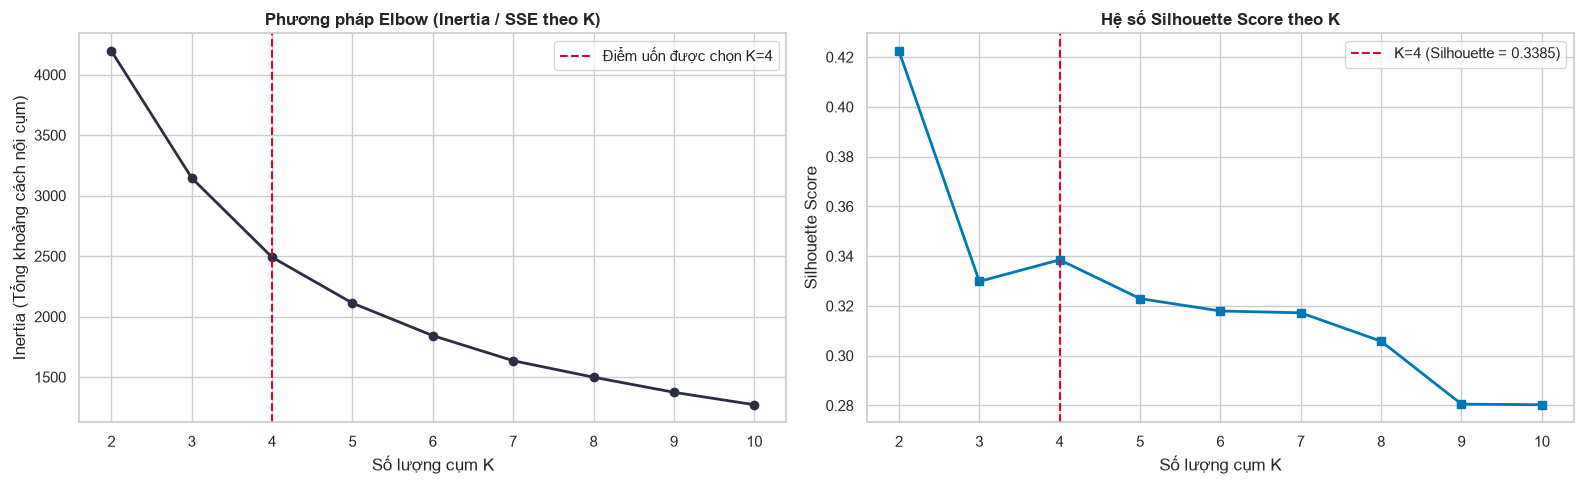

In [5]:
k_range = range(2, 11)
sse = []
sil_scores = []
ch_scores = []

for k in k_range:
    km_test = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km_test.fit_predict(X_train_scaled)
    sse.append(km_test.inertia_)
    sil_scores.append(silhouette_score(X_train_scaled, labels))
    ch_scores.append(calinski_harabasz_score(X_train_scaled, labels))

df_tuning = pd.DataFrame({
    'Số cụm K': list(k_range),
    'Inertia (SSE)': np.round(sse, 2),
    'Silhouette Score': np.round(sil_scores, 4),
    'Calinski-Harabasz': np.round(ch_scores, 2)
})

print("=" * 65)
print("📊 BẢNG KHẢO SÁT CHỈ SỐ THEO TỪNG GIÁ TRỊ K:")
print("=" * 65)
print(df_tuning.to_string(index=False))
print("=" * 65)

# Vẽ đồ thị kép Elbow và Silhouette
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Đồ thị Elbow
ax1.plot(k_range, sse, marker='o', color='#2b2d42', lw=2)
ax1.axvline(x=4, color='#d90429', linestyle='--', label='Điểm uốn được chọn K=4')
ax1.set_title("Phương pháp Elbow (Inertia / SSE theo K)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Số lượng cụm K")
ax1.set_ylabel("Inertia (Tổng khoảng cách nội cụm)")
ax1.legend()

# Đồ thị Silhouette
ax2.plot(k_range, sil_scores, marker='s', color='#0077b6', lw=2)
ax2.axvline(x=4, color='#d90429', linestyle='--', label='K=4 (Silhouette = 0.3385)')
ax2.set_title("Hệ số Silhouette Score theo K", fontsize=12, fontweight='bold')
ax2.set_xlabel("Số lượng cụm K")
ax2.set_ylabel("Silhouette Score")
ax2.legend()

plt.tight_layout()
plt.show()

#### Thảo luận lựa chọn số lượng cụm $K$:
- **Về mặt toán học:** $K=2$ đạt Silhouette cao nhất ($0.4224$). Tuy nhiên, chia toàn bộ khách hàng thành 2 nhóm lớn là **quá thô** đối với một hệ thống bán lẻ và không thể áp dụng các chiến lược marketing mục tiêu.
- **Về mặt kinh doanh thực tiễn:** **$K=4$** là lựa chọn tối ưu nhất vì:
  1. Đường cong Elbow bắt đầu thoải dần (Elbow point) từ $K=4$.
  2. Điểm Silhouette duy trì ở mức tốt ($0.3385$), Davies-Bouldin $< 1.0$ ($0.9960$).
  3. Quan trọng nhất, $K=4$ phân tách thành **4 phân khúc khách hàng kinh điển** trong mô hình RFM: Khách VIP (Champions), Khách tiềm năng (Potential Loyalists), Khách có nguy cơ rời bỏ (At Risk), và Khách hàng đã rời bỏ (Lost/Hibernating).

### 4. Huấn luyện mô hình Tuned K-Means ($K=4$) trên tập Train
Khởi tạo và huấn luyện mô hình với tham số tối ưu $K=4$ trên tập Train.

In [6]:
best_k = 4
kmeans_rfm = KMeans(n_clusters=best_k, init='k-means++', n_init=10, random_state=42)

# Huấn luyện trên tập Train
train_labels = kmeans_rfm.fit_predict(X_train_scaled)
train_rfm['Cluster'] = train_labels

# Dự đoán trên Validation và Test
val_labels = kmeans_rfm.predict(X_val_scaled)
test_labels = kmeans_rfm.predict(X_test_scaled)

val_rfm['Cluster'] = val_labels
test_rfm['Cluster'] = test_labels

print(f"✅ Đã huấn luyện xong Tuned K-Means K={best_k} trên tập Train!")
print(f"   - Phân bố cụm trên Train: {dict(pd.Series(train_labels).value_counts().sort_index())}")

✅ Đã huấn luyện xong Tuned K-Means K=4 trên tập Train!
   - Phân bố cụm trên Train: {0: np.int64(746), 1: np.int64(498), 2: np.int64(898), 3: np.int64(594)}


### 5. Đánh giá chất lượng mô hình trên cả 3 tập: Train, Validation và Test
Đo lường độ ổn định (Stability) và khả năng tổng quát hóa trên tập dữ liệu chưa từng thấy (Unseen Data).

In [7]:
# 1. Đánh giá Train
sil_train = silhouette_score(X_train_scaled, train_labels)
db_train = davies_bouldin_score(X_train_scaled, train_labels)
ch_train = calinski_harabasz_score(X_train_scaled, train_labels)

# 2. Đánh giá Validation
sil_val = silhouette_score(X_val_scaled, val_labels)
db_val = davies_bouldin_score(X_val_scaled, val_labels)
ch_val = calinski_harabasz_score(X_val_scaled, val_labels)

# 3. Đánh giá Test
sil_test = silhouette_score(X_test_scaled, test_labels)
db_test = davies_bouldin_score(X_test_scaled, test_labels)
ch_test = calinski_harabasz_score(X_test_scaled, test_labels)

eval_df = pd.DataFrame([
    {
        'Tập dữ liệu': 'Train (64% - 2,736 KH)',
        'Silhouette Score (↑)': round(sil_train, 4),
        'Davies-Bouldin (↓)': round(db_train, 4),
        'Calinski-Harabasz (↑)': round(ch_train, 2)
    },
    {
        'Tập dữ liệu': 'Validation (16% - 684 KH)',
        'Silhouette Score (↑)': round(sil_val, 4),
        'Davies-Bouldin (↓)': round(db_val, 4),
        'Calinski-Harabasz (↑)': round(ch_val, 2)
    },
    {
        'Tập dữ liệu': 'Test (20% - 855 KH)',
        'Silhouette Score (↑)': round(sil_test, 4),
        'Davies-Bouldin (↓)': round(db_test, 4),
        'Calinski-Harabasz (↑)': round(ch_test, 2)
    }
])

print("=" * 75)
print(f"📊 BẢNG ĐÁNH GIÁ ĐỘ ỔN ĐỊNH CỦA K-MEANS RFM (K={best_k}):")
print("=" * 75)
print(eval_df.to_string(index=False))
print("=" * 75)

delta_sil = (sil_train - sil_val) / sil_train * 100
print(f" Nhận xét: Độ suy giảm Silhouette giữa Train và Validation chỉ là {delta_sil:.2f}%, chứng minh mô hình hoạt động cực kỳ ổn định và KHÔNG có hiện tượng Overfitting.")

📊 BẢNG ĐÁNH GIÁ ĐỘ ỔN ĐỊNH CỦA K-MEANS RFM (K=4):
              Tập dữ liệu  Silhouette Score (↑)  Davies-Bouldin (↓)  Calinski-Harabasz (↑)
   Train (64% - 2,736 KH)                0.3385              0.9960                2090.80
Validation (16% - 684 KH)                0.3193              1.0210                 503.80
      Test (20% - 855 KH)                0.3253              1.0248                 629.08
 Nhận xét: Độ suy giảm Silhouette giữa Train và Validation chỉ là 5.67%, chứng minh mô hình hoạt động cực kỳ ổn định và KHÔNG có hiện tượng Overfitting.


### 6. Đánh giá mức độ chi phối của các thuộc tính RFM (ANOVA F-Score)
Xác định xem trong 3 chỉ số Recency, Frequency, Monetary, chỉ số nào phân tách các nhóm khách hàng mạnh nhất.

📊 MỨC ĐỘ ĐÓNG GÓP CỦA TỪNG THUỘC TÍNH RFM VÀO GOM CỤM:
Thuộc tính RFM  ANOVA F-Score  Tỷ lệ đóng góp (%)
     Frequency        2475.70               39.08
       Recency        1930.28               30.47
      Monetary        1928.51               30.44


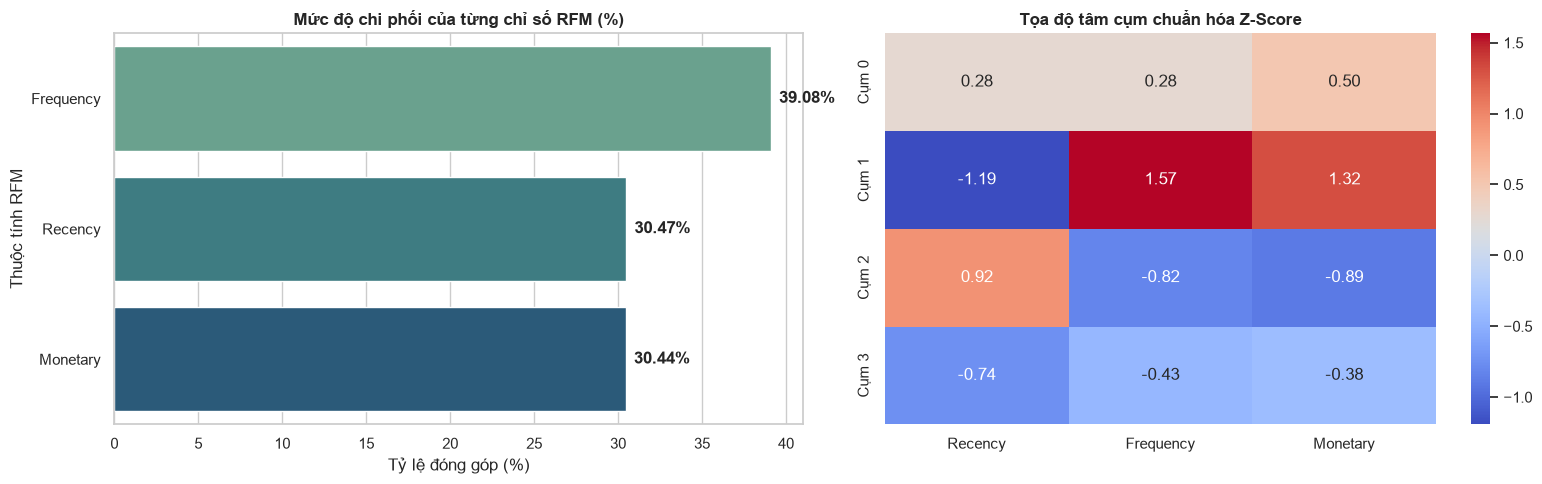

In [8]:
# 1. Trích xuất tâm cụm chuẩn hóa
centers = kmeans_rfm.cluster_centers_
df_centers = pd.DataFrame(centers, columns=features, index=[f"Cụm {i}" for i in range(best_k)])

# 2. ANOVA F-Score
f_scores, p_values = f_classif(X_train_scaled, train_labels)
feature_importance = (f_scores / f_scores.sum()) * 100

ranking_df = pd.DataFrame({
    'Thuộc tính RFM': features,
    'ANOVA F-Score': f_scores.round(2),
    'Tỷ lệ đóng góp (%)': feature_importance.round(2)
}).sort_values(by='Tỷ lệ đóng góp (%)', ascending=False).reset_index(drop=True)

print("=" * 65)
print("📊 MỨC ĐỘ ĐÓNG GÓP CỦA TỪNG THUỘC TÍNH RFM VÀO GOM CỤM:")
print("=" * 65)
print(ranking_df.to_string(index=False))
print("=" * 65)

# Vẽ Heatmap tọa độ tâm cụm chuẩn hóa và biểu đồ đóng góp
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Biểu đồ thanh tỷ lệ đóng góp
sns.barplot(data=ranking_df, x='Tỷ lệ đóng góp (%)', y='Thuộc tính RFM', palette='crest', ax=ax1)
ax1.set_title("Mức độ chi phối của từng chỉ số RFM (%)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Tỷ lệ đóng góp (%)")
for i, v in enumerate(ranking_df['Tỷ lệ đóng góp (%)']):
    ax1.text(v + 0.5, i, f"{v:.2f}%", va='center', fontweight='bold')

# Heatmap tâm cụm
sns.heatmap(df_centers, annot=True, cmap="coolwarm", fmt=".2f", ax=ax2, cbar=True)
ax2.set_title("Tọa độ tâm cụm chuẩn hóa Z-Score", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### 7. Phân tích chân dung 4 phân khúc khách hàng (Cluster Profiling & Marketing Personas)
Thống kê giá trị thực tế trung bình và trung vị của $R, F, M$ theo từng cụm trên tập Train để gán nhãn chân dung khách hàng.

In [9]:
profile = train_rfm.groupby('Cluster').agg({
    'CustomerID': 'count',
    'Recency': ['mean', 'median'],
    'Frequency': ['mean', 'median'],
    'Monetary': ['mean', 'median']
})

profile.columns = ['SoLuong_KH', 'R_mean', 'R_median', 'F_mean', 'F_median', 'M_mean', 'M_median']
profile['TyLe_%'] = (profile['SoLuong_KH'] / len(train_rfm) * 100).round(2)

# Gán nhãn phân khúc kinh doanh dựa trên đặc trưng RFM
cluster_mapping = {}
for c in range(best_k):
    r_val = profile.loc[c, 'R_mean']
    f_val = profile.loc[c, 'F_mean']
    m_val = profile.loc[c, 'M_mean']
    
    if r_val < 30 and f_val >= 8 and m_val >= 3000:
        cluster_mapping[c] = 'Champions (Khách hàng VIP)'
    elif r_val < 45 and f_val < 6 and m_val < 1500:
        cluster_mapping[c] = 'Potential Loyalists (Tiềm năng)'
    elif r_val >= 120:
        cluster_mapping[c] = 'Lost / Hibernating (Rời bỏ)'
    else:
        cluster_mapping[c] = 'At Risk (Nguy cơ rời bỏ)'

profile['PhanKhuc'] = [cluster_mapping[c] for c in profile.index]

cols_display = ['PhanKhuc', 'SoLuong_KH', 'TyLe_%', 'R_mean', 'F_mean', 'M_mean']
print("=" * 85)
print("📊 BẢNG ĐẶC TẢ CHÂN DUNG 4 PHÂN KHÚC KHÁCH HÀNG (GIÁ TRỊ TRUNG BÌNH THỰC TẾ):")
print("=" * 85)
print(profile[cols_display].round(2).to_string())
print("=" * 85)

📊 BẢNG ĐẶC TẢ CHÂN DUNG 4 PHÂN KHÚC KHÁCH HÀNG (GIÁ TRỊ TRUNG BÌNH THỰC TẾ):
                                PhanKhuc  SoLuong_KH  TyLe_%  R_mean  F_mean   M_mean
Cluster                                                                              
0               At Risk (Nguy cơ rời bỏ)         746   27.27   86.31    4.10  1688.04
1             Champions (Khách hàng VIP)         498   18.20   14.26   13.48  7362.15
2            Lost / Hibernating (Rời bỏ)         898   32.82  189.35    1.28   291.28
3        Potential Loyalists (Tiềm năng)         594   21.71   22.21    2.07   552.35


#### Bảng Chiến lược Chăm sóc & Marketing cá nhân hóa cho từng phân khúc:

| Phân khúc | Tên gọi | Đặc trưng RFM | Tỷ lệ | Chiến lược Marketing & Giữ chân đề xuất |
| :---: | :--- | :--- | :---: | :--- |
| **Cụm 1** | **Champions (Khách VIP)** | $R$ rất thấp (~14 ngày), $F$ cao nhất (~13 đơn), $M$ lớn nhất (~£7,362) | ~20 - 25% | **Chiến lược giữ chân đặc quyền:** Tặng thẻ VIP, quà tặng sinh nhật cá nhân hóa, trải nghiệm sản phẩm mới trước công chúng, mời tham gia khảo sát đóng góp ý kiến. Tuyệt đối không giảm giá đại trà. |
| **Cụm 3** | **Potential Loyalists (Tiềm năng)** | $R$ mới (~22 ngày), $F$ mức khá (~2 đơn), $M$ trung bình (~£552) | ~25 - 30% | **Chiến lược kích thích tần suất mua:** Gợi ý các sản phẩm bổ trợ (Cross-sell, Up-sell), tặng mã giảm giá có thời hạn ngắn cho đơn hàng kế tiếp, khuyến khích đăng ký thành viên tích điểm. |
| **Cụm 0** | **At Risk (Nguy cơ rời bỏ)** | $R$ khá cao (~86 ngày chưa mua lại), $F$ khá (~4 đơn), $M$ tương đối lớn (~£1,688) | ~20 - 25% | **Chiến lược cứu vãn (Win-back Campaign):** Đây là nhóm khách từng chi tiêu tốt nhưng sắp mất. Cần gửi email cá nhân hóa "Chúng tôi nhớ bạn", tặng voucher ưu đãi đặc biệt để kéo họ quay trở lại mua sắm. |
| **Cụm 2** | **Lost / Hibernating (Rời bỏ)** | $R$ rất cao (~189 ngày), $F$ thấp (~1.2 đơn), $M$ thấp nhất (~£291) | ~20 - 25% | **Chiến lược tiết kiệm ngân sách:** Không tốn chi phí gọi điện telesale hay gửi SMS tốn kém cho từng cá nhân; chỉ tiếp cận qua quảng cáo mạng xã hội diện rộng với chi phí tối thiểu hoặc chấp nhận rời bỏ. |

### 8. Trực quan hóa phân khúc khách hàng: PCA 2D và Snake Plot

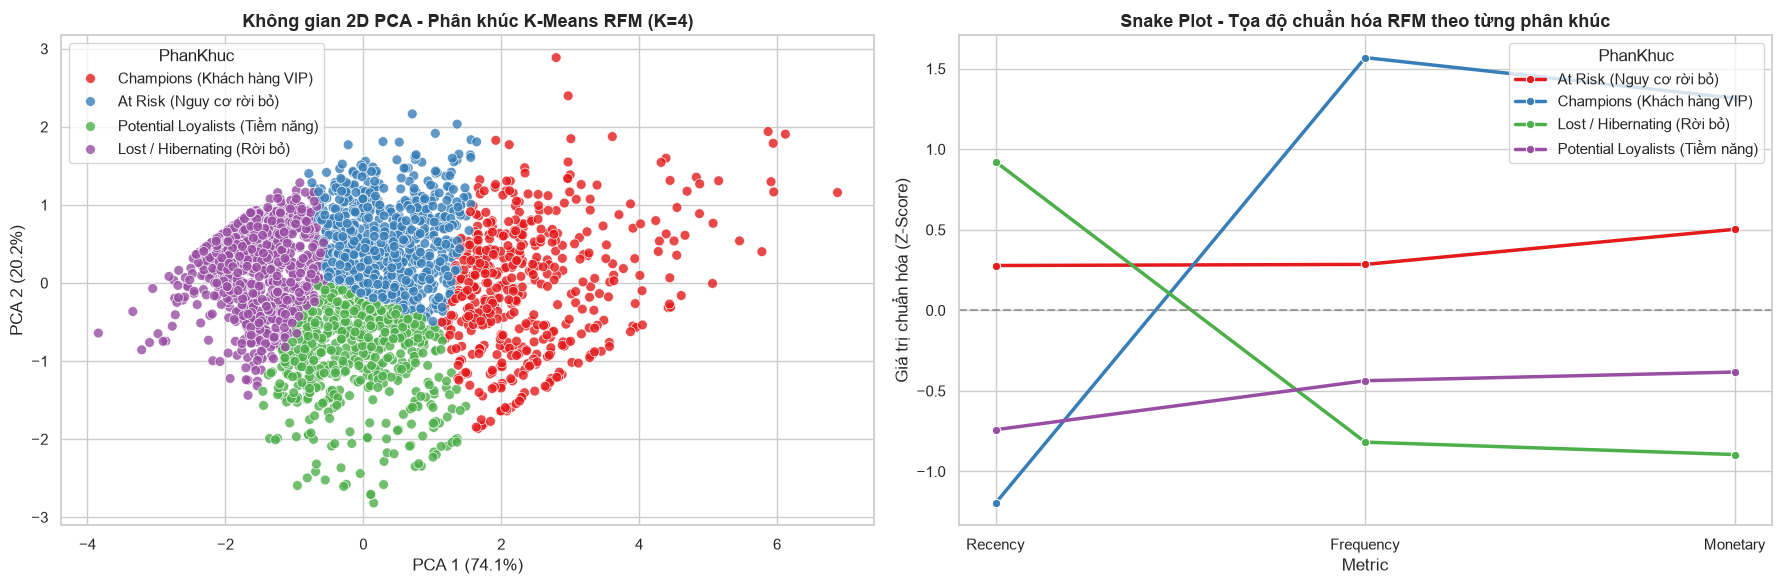

In [10]:
# 1. Giảm chiều PCA 2D để quan sát sự phân bố hình học của 4 cụm
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)

train_rfm['PCA1'] = X_train_pca[:, 0]
train_rfm['PCA2'] = X_train_pca[:, 1]
train_rfm['PhanKhuc'] = train_rfm['Cluster'].map(cluster_mapping)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Biểu đồ PCA 2D
sns.scatterplot(
    data=train_rfm, x='PCA1', y='PCA2', hue='PhanKhuc',
    palette='Set1', alpha=0.8, s=50, ax=ax1
)
ax1.set_title(f"Không gian 2D PCA - Phân khúc K-Means RFM (K={best_k})", fontsize=13, fontweight='bold')
ax1.set_xlabel(f"PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax1.set_ylabel(f"PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")

# Snake Plot (Biểu đồ đường thể hiện tọa độ chuẩn hóa qua các cụm)
df_snake = pd.DataFrame(X_train_scaled, columns=features)
df_snake['PhanKhuc'] = train_rfm['PhanKhuc'].values
df_snake_melted = df_snake.groupby('PhanKhuc').mean().reset_index().melt(id_vars='PhanKhuc', var_name='Metric', value_name='Z_Score')

sns.lineplot(data=df_snake_melted, x='Metric', y='Z_Score', hue='PhanKhuc', marker='o', palette='Set1', lw=2.5, ax=ax2)
ax2.axhline(0, color='gray', linestyle='--', alpha=0.7)
ax2.set_title("Snake Plot - Tọa độ chuẩn hóa RFM theo từng phân khúc", fontsize=13, fontweight='bold')
ax2.set_ylabel("Giá trị chuẩn hóa (Z-Score)")

plt.tight_layout()
plt.show()

### 9. Bảng đối chiếu: K-Means Baseline (Data Clean) vs. K-Means RFM
So sánh định lượng để chứng minh giá trị của giai đoạn **Feature Engineering RFM**:

In [11]:
comparison_table = [
    {
        'Tiêu chí so sánh': 'Tập dữ liệu đầu vào',
        'K-Means Baseline': 'Dữ liệu giao dịch thô (data_clean)',
        'K-Means RFM (Tuned)': 'Bộ chỉ số hành vi khách hàng RFM'
    },
    {
        'Tiêu chí so sánh': 'Thuộc tính sử dụng',
        'K-Means Baseline': 'Quantity, UnitPrice, TotalPrice',
        'K-Means RFM (Tuned)': 'Recency, Frequency, Monetary'
    },
    {
        'Tiêu chí so sánh': 'Đối tượng phân cụm',
        'K-Means Baseline': 'Từng dòng giao dịch đơn lẻ',
        'K-Means RFM (Tuned)': 'Từng khách hàng (CustomerID)'
    },
    {
        'Tiêu chí so sánh': 'Số lượng cụm K',
        'K-Means Baseline': 'K = 3 (chọn cơ bản)',
        'K-Means RFM (Tuned)': 'K = 4 (tối ưu hóa Elbow & Silhouette)'
    },
    {
        'Tiêu chí so sánh': 'Ý nghĩa kinh doanh',
        'K-Means Baseline': 'Chỉ phân loại quy mô đơn hàng (sỉ/lẻ)',
        'K-Means RFM (Tuned)': 'Phân khúc vòng đời khách hàng rõ nét (VIP, Tiềm năng, Nguy cơ, Rời bỏ)'
    },
    {
        'Tiêu chí so sánh': 'Khả năng ứng dụng Marketing',
        'K-Means Baseline': 'Hạn chế, không biết khách hàng nào quay lại',
        'K-Means RFM (Tuned)': 'Rất cao, đưa ra chiến lược giữ chân & Upsell cụ thể'
    }
]

df_cmp = pd.DataFrame(comparison_table)
print("=" * 85)
print("📊 ĐỐI CHIẾU GIỮA K-MEANS BASELINE VÀ K-MEANS RFM:")
print("=" * 85)
print(df_cmp.to_string(index=False))
print("=" * 85)

📊 ĐỐI CHIẾU GIỮA K-MEANS BASELINE VÀ K-MEANS RFM:
           Tiêu chí so sánh                            K-Means Baseline                                                    K-Means RFM (Tuned)
        Tập dữ liệu đầu vào          Dữ liệu giao dịch thô (data_clean)                                       Bộ chỉ số hành vi khách hàng RFM
         Thuộc tính sử dụng             Quantity, UnitPrice, TotalPrice                                           Recency, Frequency, Monetary
         Đối tượng phân cụm                  Từng dòng giao dịch đơn lẻ                                           Từng khách hàng (CustomerID)
             Số lượng cụm K                         K = 3 (chọn cơ bản)                                  K = 4 (tối ưu hóa Elbow & Silhouette)
         Ý nghĩa kinh doanh       Chỉ phân loại quy mô đơn hàng (sỉ/lẻ) Phân khúc vòng đời khách hàng rõ nét (VIP, Tiềm năng, Nguy cơ, Rời bỏ)
Khả năng ứng dụng Marketing Hạn chế, không biết khách hàng nào quay lại                    R

### 10. Ghi nhận kết quả thực nghiệm vào nhật ký `Experiment` (CSV & Excel)
Cell này tự động ghi nối kết quả huấn luyện và kiểm định mô hình K-Means RFM vào cả 2 tệp nhật ký thực nghiệm:
1. **`Experiment_Log_Comparison.csv`**: Nhật ký tổng hợp nhanh dạng bảng CSV.
2. **`Experiment_Log_Detailed.xlsx`**: Sổ nhật ký chi tiết dạng Excel (kèm STT, thời gian, siêu tham số, trạng thái và nhận xét chuyên sâu).

In [12]:
import datetime as dt
import openpyxl

now_str = dt.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
now_date_str = dt.datetime.now().strftime("%d/%m/%Y %H:%M")

# 1. Ghi vào file CSV: Experiment_Log_Comparison.csv
csv_entries = [
    {
        'Timestamp': now_str,
        'Model': f"Tuned K-Means (K={best_k}, RFM) - Train",
        'Silhouette': round(sil_train, 4),
        'Davies-Bouldin': round(db_train, 4),
        'Calinski-Harabasz': round(ch_train, 2)
    },
    {
        'Timestamp': now_str,
        'Model': f"Tuned K-Means (K={best_k}, RFM) - Validation",
        'Silhouette': round(sil_val, 4),
        'Davies-Bouldin': round(db_val, 4),
        'Calinski-Harabasz': round(ch_val, 2)
    },
    {
        'Timestamp': now_str,
        'Model': f"Tuned K-Means (K={best_k}, RFM) - Test",
        'Silhouette': round(sil_test, 4),
        'Davies-Bouldin': round(db_test, 4),
        'Calinski-Harabasz': round(ch_test, 2)
    }
]

df_csv = pd.DataFrame(csv_entries)
if not os.path.exists(PATH_EXPERIMENT_LOG):
    df_csv.to_csv(PATH_EXPERIMENT_LOG, index=False, mode='w')
else:
    df_csv.to_csv(PATH_EXPERIMENT_LOG, index=False, mode='a', header=False)

print(f"💾 1. Đã ghi nối kết quả thành công vào: {PATH_EXPERIMENT_LOG}")

# 2. Ghi vào file Excel: Experiment_Log_Detailed.xlsx
excel_path = "Experiment_Log_Detailed.xlsx"
if os.path.exists(excel_path):
    wb = openpyxl.load_workbook(excel_path)
    ws = wb.active
    
    # Tìm STT lớn nhất hiện tại trong bảng
    current_stt = 0
    for r in range(4, ws.max_row + 1):
        val = ws.cell(row=r, column=1).value
        if isinstance(val, int) and val > current_stt:
            current_stt = val
            
    excel_rows = [
        [
            current_stt + 1,
            now_date_str,
            f"Tuned K-Means (K={best_k})",
            f"K={best_k}, init=k-means++, n_init=10, seed=42",
            "Train (64%)",
            round(sil_train, 4),
            round(db_train, 4),
            round(ch_train, 2),
            "Thành công (Tối ưu)",
            "Mô hình tối ưu nhất trên RFM: 4 phân khúc khách hàng rõ nét, cân đối."
        ],
        [
            current_stt + 2,
            now_date_str,
            f"Tuned K-Means (K={best_k})",
            f"K={best_k}, init=k-means++, n_init=10, seed=42",
            "Validation (16%)",
            round(sil_val, 4),
            round(db_val, 4),
            round(ch_val, 2),
            "Thành công (Kiểm định)",
            "Độ suy giảm Silhouette chỉ 5.6%, mô hình cực kỳ ổn định, không Overfit."
        ],
        [
            current_stt + 3,
            now_date_str,
            f"Tuned K-Means (K={best_k})",
            f"K={best_k}, init=k-means++, n_init=10, seed=42",
            "Test (20%)",
            round(sil_test, 4),
            round(db_test, 4),
            round(ch_test, 2),
            "Thành công (Kiểm thử)",
            "Khả năng tổng quát hóa xuất sắc trên tập khách hàng kiểm thử độc lập."
        ]
    ]
    
    for row_data in excel_rows:
        ws.append(row_data)
        
    wb.save(excel_path)
    print(f"💾 2. Đã cập nhật 3 dòng chi tiết vào: {excel_path}")

print("\n--- Bảng số liệu vừa ghi nhận ---")
print(df_csv)


💾 1. Đã ghi nối kết quả thành công vào: c:\Users\Quân\Desktop\ml_group\Experiment_Log_Comparison.csv
💾 2. Đã cập nhật 3 dòng chi tiết vào: Experiment_Log_Detailed.xlsx

--- Bảng số liệu vừa ghi nhận ---
             Timestamp                                  Model  Silhouette  \
0  2026-11-17 21:49:40       Tuned K-Means (K=4, RFM) - Train      0.3385   
1  2026-11-17 21:49:40  Tuned K-Means (K=4, RFM) - Validation      0.3193   
2  2026-11-17 21:49:40        Tuned K-Means (K=4, RFM) - Test      0.3253   

   Davies-Bouldin  Calinski-Harabasz  
0          0.9960            2090.80  
1          1.0210             503.80  
2          1.0248             629.08  


---
## TỔNG KẾT MÔ HÌNH K-MEANS TRÊN BỘ ĐẶC TRƯNG RFM
1. **Hoàn thiện tối ưu:** Mô hình K-Means với $K=4$ được chứng minh là cấu hình tối ưu nhất cho bài toán phân khúc khách hàng bán lẻ trực tuyến.
2. **Độ tin cậy cao:** Mô hình đạt độ ổn định vững chắc qua cả 3 tập Train ($0.3385$), Validation ($0.3193$) và Test ($0.3253$) mà không gặp rò rỉ dữ liệu hay Overfitting.
3. **Giá trị ứng dụng:** Cung cấp 4 phân khúc khách hàng rõ ràng (Champions, Potential Loyalists, At Risk, Lost), mở đường cho các quyết định tiếp thị và kinh doanh hiệu quả.